# Prototype run 

Input: latitude, longitude, start month. Output: 12 monthly land-cover maps, class percentages,
month-to-month and total change (percentage points) with significance flags, error-adjusted
percentages, uncertainty, agreement with Dynamic World, and an interactive HTML report.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!rm -rf /content/s1lulc-repo /content/results
!unzip -q -o /content/drive/MyDrive/s1lulc-repo.zip -d /content
!unzip -q -o /content/drive/MyDrive/results.zip -d /content/results
%cd /content/s1lulc-repo
!pip -q install -e ".[gee,geo]" segmentation-models-pytorch matplotlib

Mounted at /content/drive
/content/s1lulc-repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for s1lulc (pyproject.toml) ... done


In [ ]:
import ee
ee.Authenticate()
PROJECT = "peaceful-basis-316309"          # Earth Engine Cloud project ID
ee.Initialize(project=PROJECT)

## Choose the location and start month
The 12-month window must be complete (the tool tells you the latest possible start month).

In [ ]:
LAT, LON = 48.14, 11.42              # Munich-Freiham (case study)
START = "2025-10"                    # first of the 12 months, YYYY-MM
OUT = "/content/drive/MyDrive/s1lulc_predictions/munich_freiham"
BUNDLE = "/content/results/final_bundle"

In [ ]:
!s1lulc predict --lat {LAT} --lon {LON} --start {START} --bundle {BUNDLE} --project {PROJECT} --out "{OUT}" --cache /content/drive/MyDrive/s1lulc_cache

2026-11-09 07:42:27,390 INFO s1lulc.prototype.run: area of interest EPSG:32632, 1000x1000 px, 2025-10 .. 2026-09
2026-11-09 07:42:40,902 INFO s1lulc.prototype.run: running model on 12 months (cuda)
2026-11-09 07:42:55,172 INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-09 07:42:55,174 INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-09 07:42:55,175 INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-09 07:42:55,176 INFO matplotlib.category: Using categorical units to plot 

## Results

,class,first_month_pct,last_month_pct,change_pp,significant,noise_floor_pp,change_smoothed_pp,gross_gain_pp,gross_loss_pp
0,tree_cover,49.458,46.976,-2.482,False,11.918,-2.377,3.787,6.269
1,low_vegetation,17.857,20.059,2.202,False,16.068,2.540,5.114,2.912
2,cropland,6.477,5.075,-1.402,False,50.788,-1.609,1.986,3.388
3,built_up,25.889,27.459,1.571,False,2.012,1.355,3.731,2.160
4,bare_sparse,0.083,0.068,-0.015,False,22.560,-0.013,0.056,0.071
5,water,0.206,0.308,0.102,False,0.754,0.062,0.133,0.030
6,wetland,0.030,0.055,0.024,False,9.122,0.042,0.038,0.014


class,bare_sparse,built_up,cropland,low_vegetation,tree_cover,water,wetland
month,,,,,,,
2025-10,0.08,25.89,6.48,17.86,49.46,0.21,0.03
2025-11,0.07,25.98,7.69,17.37,48.60,0.25,0.03
2025-12,0.08,28.12,15.26,12.61,43.44,0.41,0.07
2026-01,0.12,27.44,14.80,12.06,45.07,0.42,0.11
2026-02,0.42,28.04,12.53,15.08,43.31,0.52,0.10
2026-03,0.11,27.49,11.04,14.41,46.59,0.34,0.02
2026-04,0.08,28.67,10.84,15.29,44.75,0.33,0.03
2026-05,0.04,27.15,6.67,20.03,45.83,0.26,0.03
2026-06,0.07,27.27,7.85,19.32,45.22,0.22,0.06


class,bare_sparse,built_up,cropland,low_vegetation,tree_cover,water,wetland
to,,,,,,,
2025-11,-0.01,0.09,1.22,-0.49,-0.86,0.04,0.00
2025-12,0.01,2.14,7.57,-4.76,-5.16,0.16,0.04
2026-01,0.03,-0.68,-0.47,-0.55,1.62,0.01,0.04
2026-02,0.30,0.60,-2.26,3.02,-1.76,0.10,-0.01
2026-03,-0.31,-0.54,-1.49,-0.67,3.28,-0.18,-0.08
2026-04,-0.02,1.18,-0.21,0.88,-1.83,-0.01,0.01
2026-05,-0.04,-1.52,-4.17,4.74,1.07,-0.08,-0.01
2026-06,0.03,0.12,1.18,-0.70,-0.61,-0.04,0.03
2026-07,-0.02,-0.64,-1.35,0.06,1.90,0.01,0.05


class_shares.png


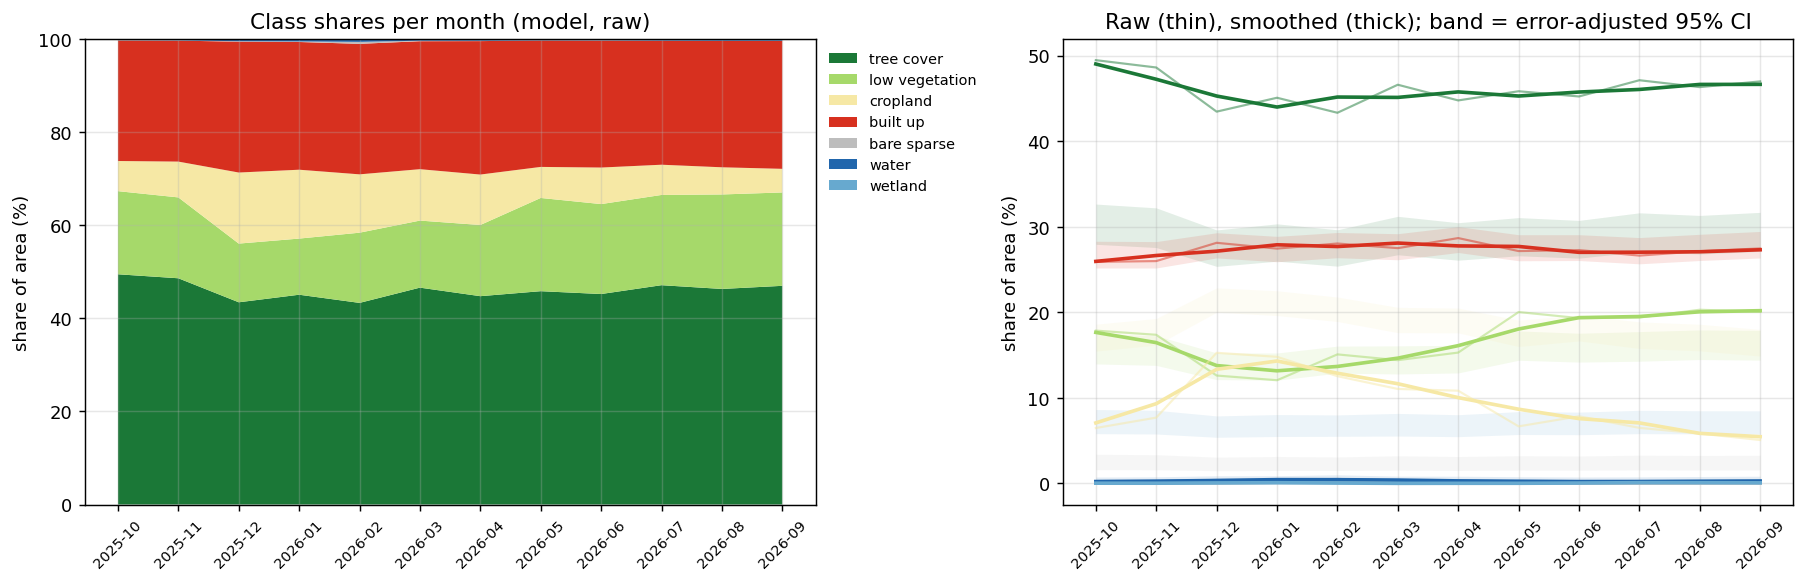

dynamic_world_agreement.png


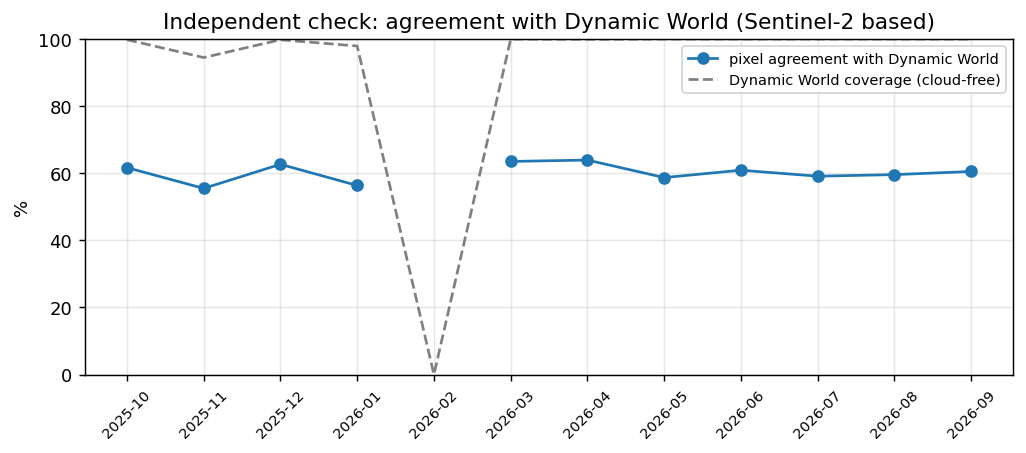

month-to-month_change.png


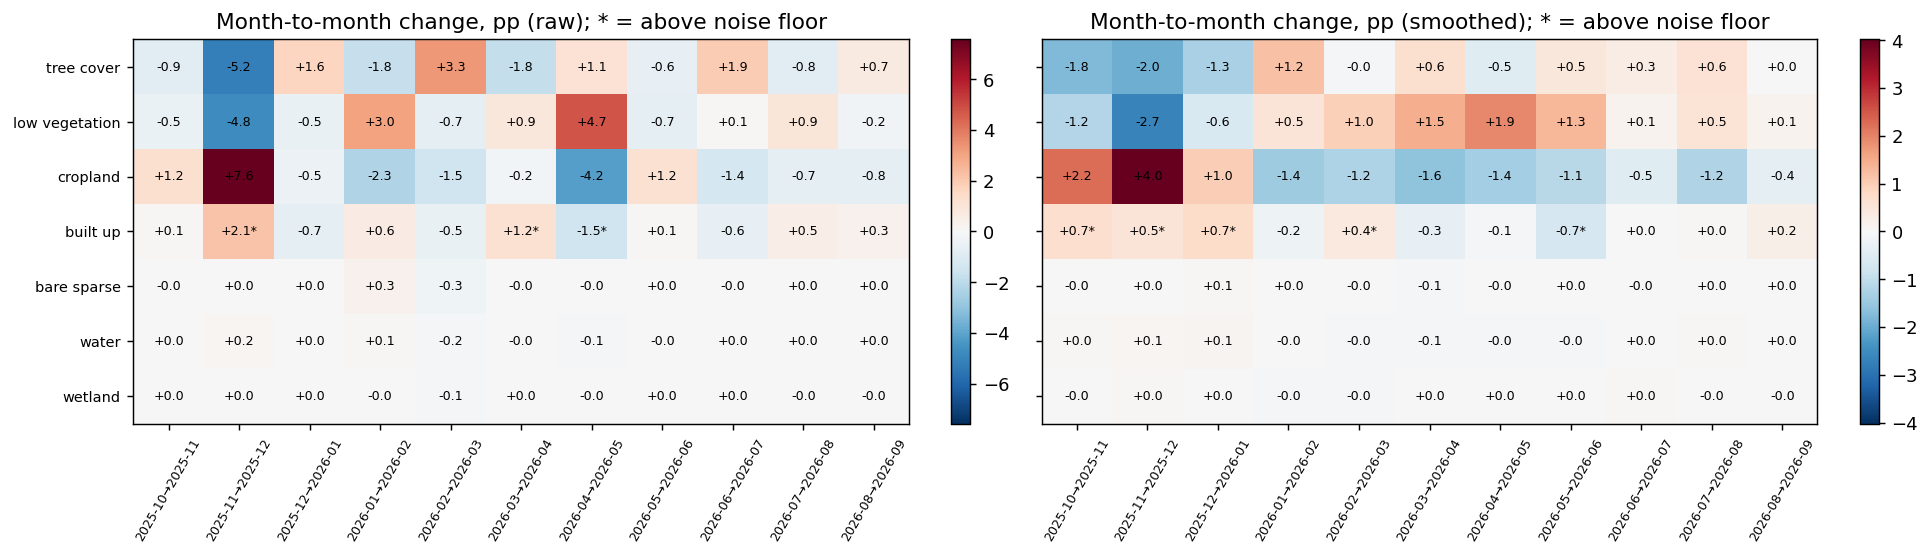

monthly_maps_dynamic_world.png


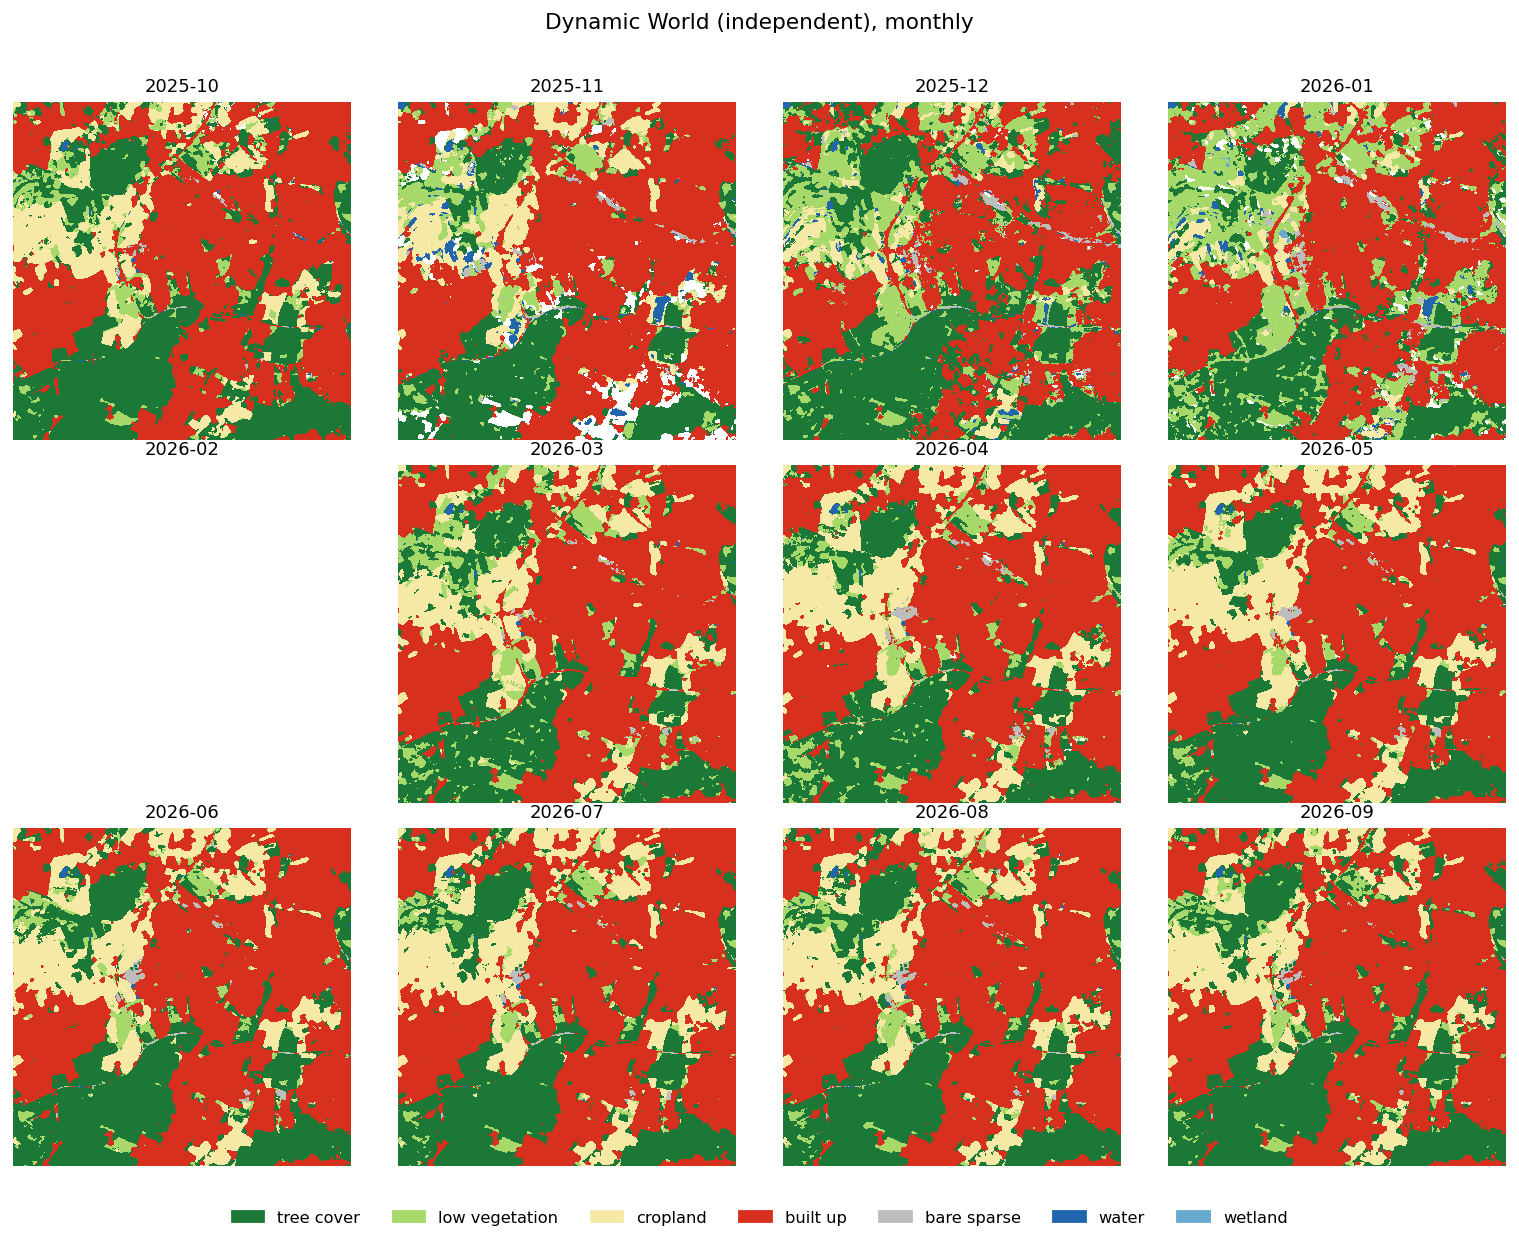

monthly_maps_raw.png


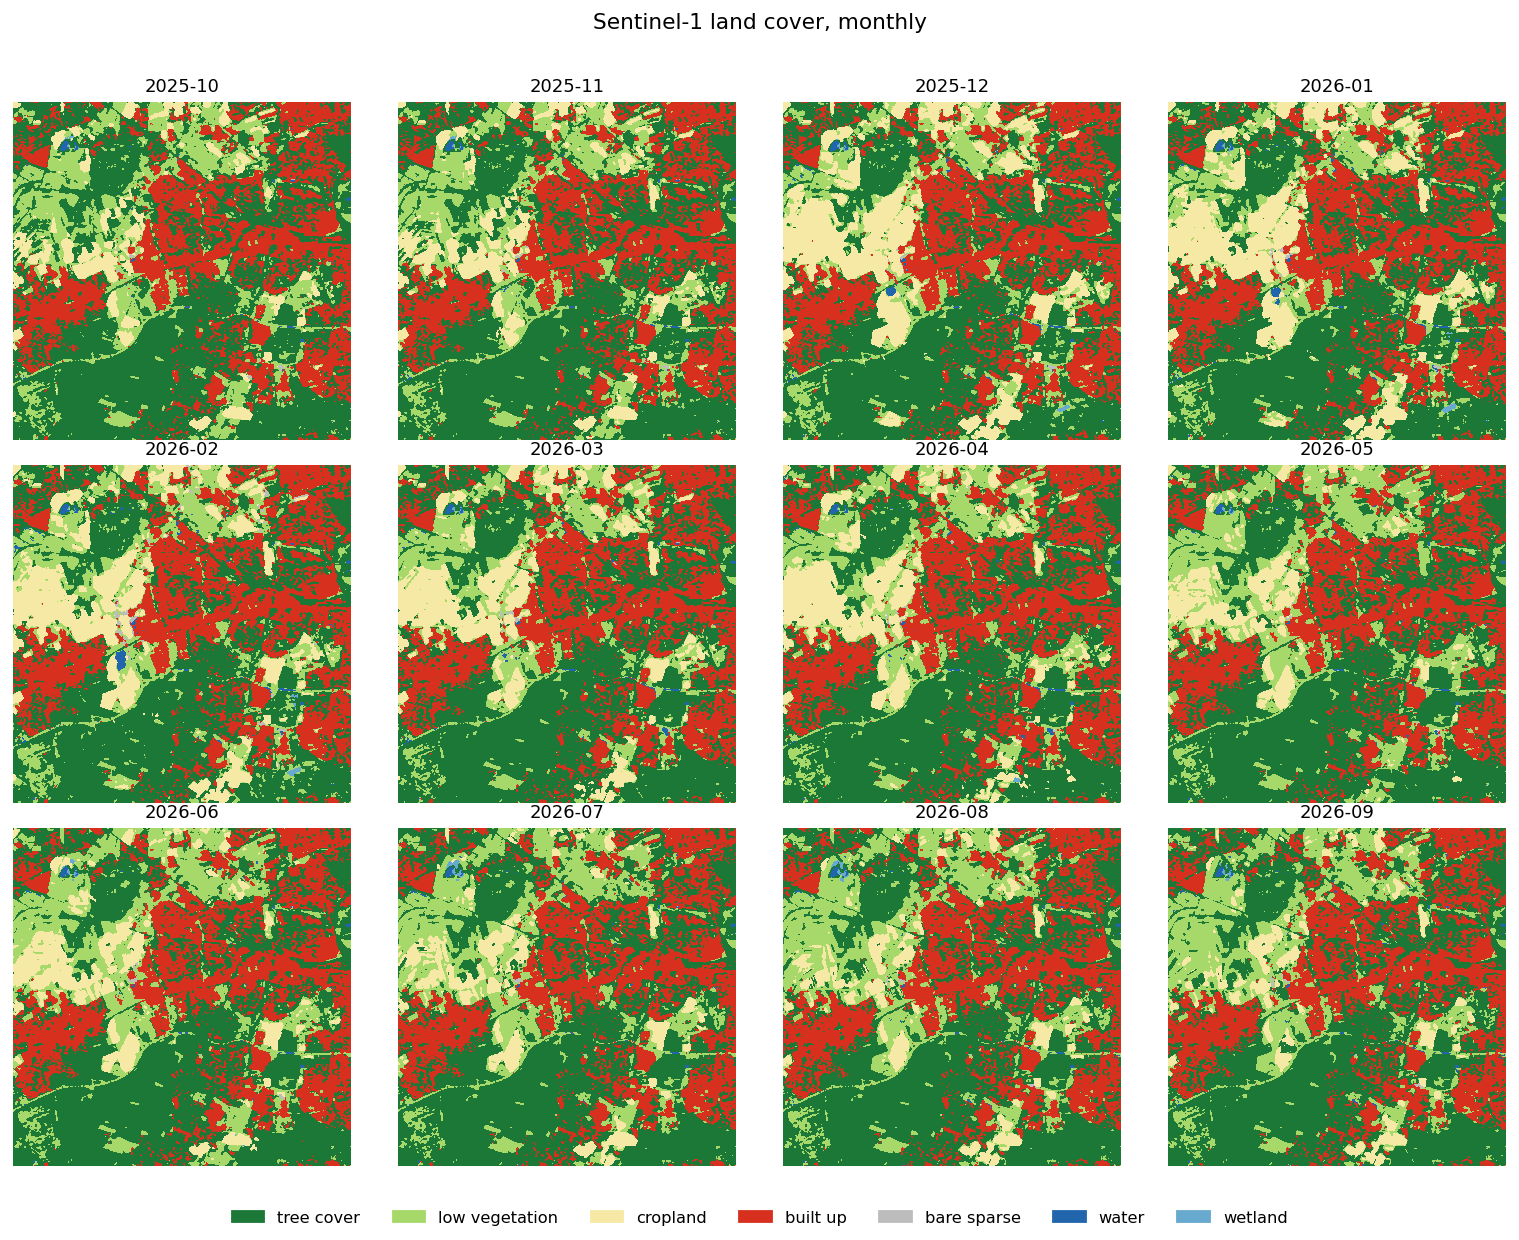

uncertainty_label_switches_gross_vs_net.png


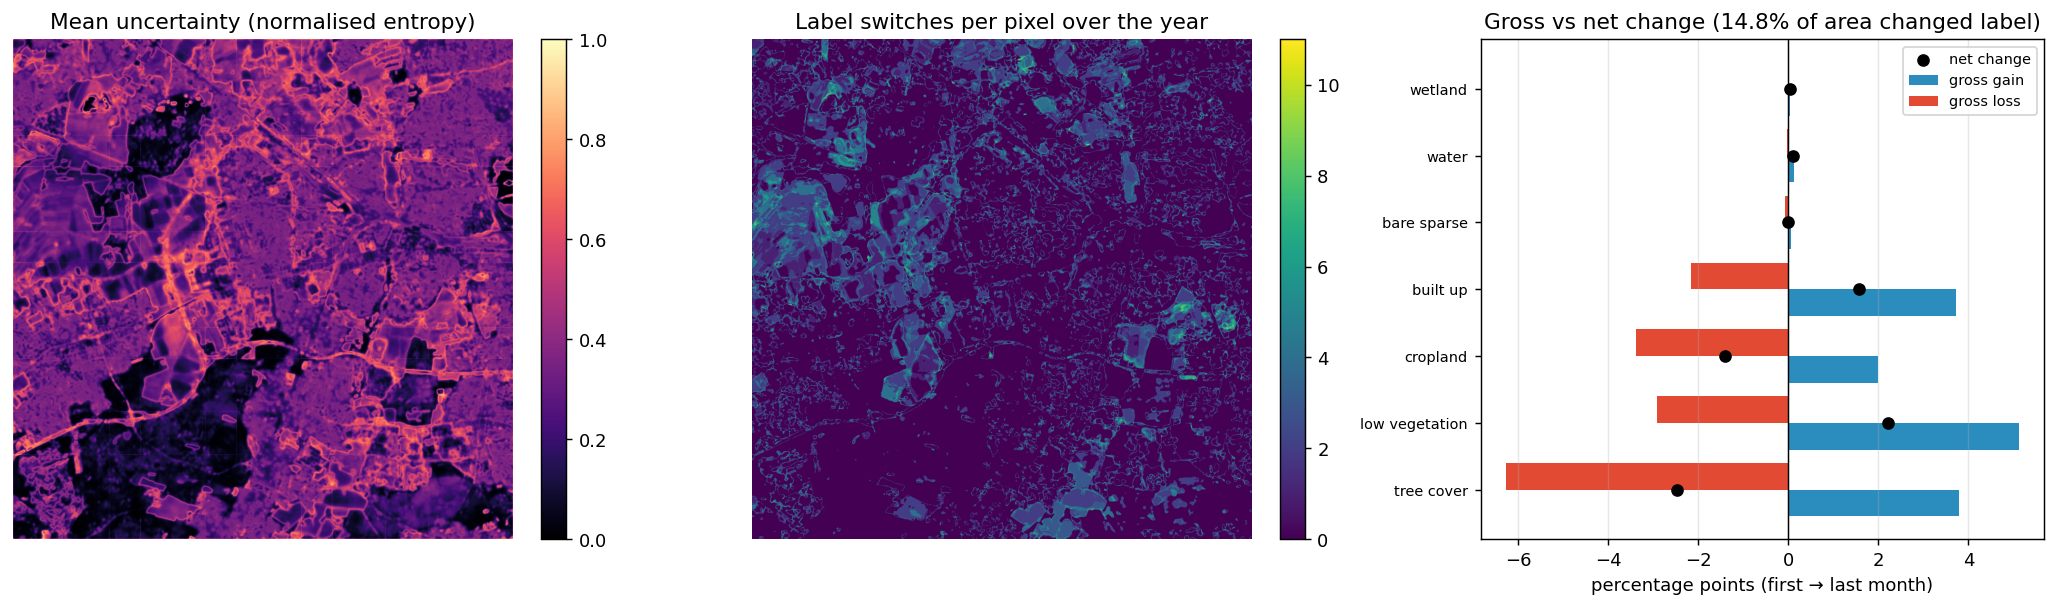

In [ ]:
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
O = Path(OUT)
display(pd.read_csv(O / "change_total.csv"))
display(pd.read_csv(O / "class_shares.csv").pivot(index="month", columns="class", values="share_pct").round(2))
display(pd.read_csv(O / "change_month_to_month.csv").pivot(index="to", columns="class", values="change_pp").round(2))
for f in sorted(O.glob("*.png")):
    print(f.name); display(Image(str(f)))

In [ ]:
from google.colab import files
files.download(str(O / "report.html"))     # open it in your browser

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>